Predictive Customer Churn Classifier (Random Forest & XGBoost)

In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [7]:
df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
print("Dataset Shape:", df.shape)

df.info()

df.describe()

Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [10]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Churn
No     5174
Yes    1869
Name: count, dtype: int64


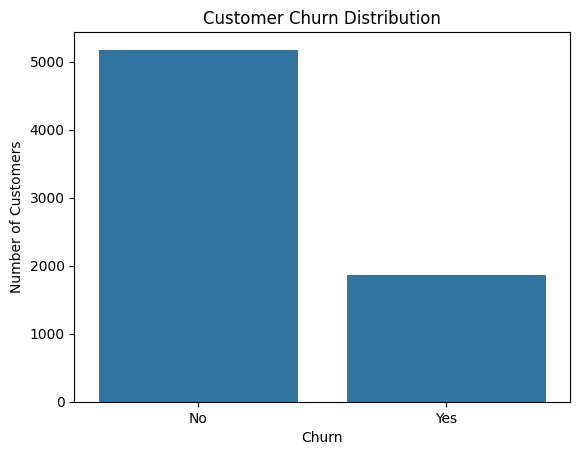

In [11]:
print(df['Churn'].value_counts())

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print(df['TotalCharges'].dtype)

print(df['TotalCharges'].isnull().sum())

float64
11


In [13]:
df = df.drop(columns=['customerID'])

X = df.drop(columns=['Churn'])

y = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Independent Variables:", X.shape)
print("Dependent Variable:", y.shape)

Independent Variables: (7043, 19)
Dependent Variable: (7043,)


In [14]:
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=['object']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [15]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [17]:
negative = (y_train == 0).sum()

positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Non-churn customers:", negative)

print("Churn customers:", positive)

print("Class imbalance ratio:", scale_pos_weight)

Non-churn customers: 4139
Churn customers: 1495
Class imbalance ratio: 2.768561872909699


In [18]:
class_weight='balanced'

In [19]:
scale_pos_weight=scale_pos_weight

In [20]:
rf_model = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf_model)
])

In [21]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [22]:
rf_predictions = rf_pipeline.predict(X_test)

rf_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

print("Predictions:")

print(rf_predictions[:10])

Predictions:
[0 1 0 0 0 1 0 0 0 1]


In [23]:
xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

In [24]:
xgb_pipeline.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [25]:
xgb_predictions = xgb_pipeline.predict(X_test)

xgb_probabilities = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Predictions:")

print(xgb_predictions[:10])

Predictions:
[0 1 0 1 0 1 1 0 0 1]


In [27]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Random Forest
rf_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1
)

# XGBoost
xgb_scores = cross_val_score(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=1
)

print("Random Forest ROC-AUC Scores:")
print(rf_scores)

print("\nRandom Forest Mean ROC-AUC:")
print(rf_scores.mean())

print("\nXGBoost ROC-AUC Scores:")
print(xgb_scores)

print("\nXGBoost Mean ROC-AUC:")
print(xgb_scores.mean())

Random Forest ROC-AUC Scores:
[0.83174996 0.82629902 0.83882265 0.83643748 0.85269722]

Random Forest Mean ROC-AUC:
0.8372012638498422

XGBoost ROC-AUC Scores:
[0.83645768 0.82391183 0.84207624 0.85491493 0.84722958]

XGBoost Mean ROC-AUC:
0.8409180534507119


In [28]:
rf_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_probabilities
)

print("Random Forest ROC-AUC:", rf_auc)

print("XGBoost ROC-AUC:", xgb_auc)

Random Forest ROC-AUC: 0.8340644294608489
XGBoost ROC-AUC: 0.8389483065953653


In [29]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],

    'Cross Validation ROC-AUC': [
        rf_scores.mean(),
        xgb_scores.mean()
    ],

    'Test ROC-AUC': [
        rf_auc,
        xgb_auc
    ]
})

print(results)

           Model  Cross Validation ROC-AUC  Test ROC-AUC
0  Random Forest                  0.837201      0.834064
1        XGBoost                  0.840918      0.838948


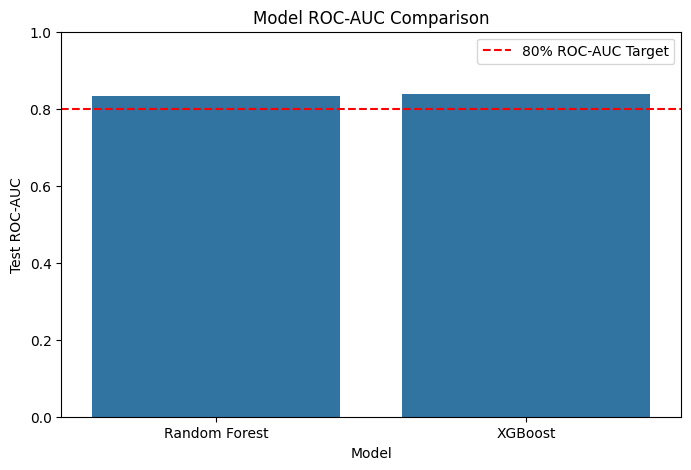

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Test ROC-AUC'
)

plt.axhline(
    y=0.80,
    color='red',
    linestyle='--',
    label='80% ROC-AUC Target'
)

plt.title("Model ROC-AUC Comparison")

plt.ylim(0, 1)

plt.legend()

plt.show()

In [31]:
print("Random Forest Classification Report")

print(
    classification_report(
        y_test,
        rf_predictions
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1035
           1       0.58      0.64      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [32]:
print("XGBoost Classification Report")

print(
    classification_report(
        y_test,
        xgb_predictions
    )
)

XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



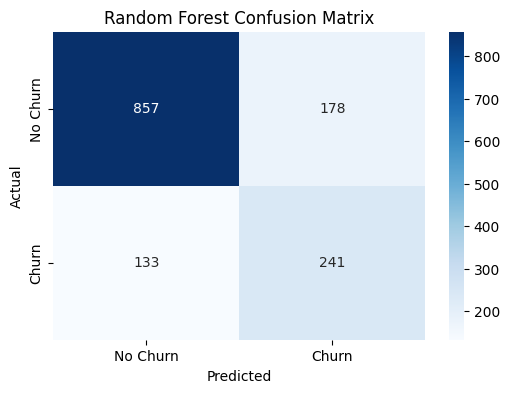

In [33]:
rf_cm = confusion_matrix(
    y_test,
    rf_predictions
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

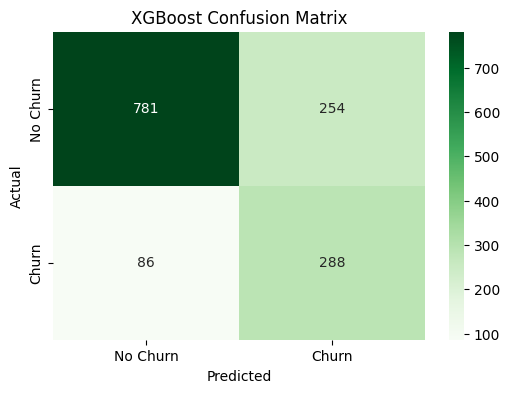

In [34]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_predictions
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("XGBoost Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

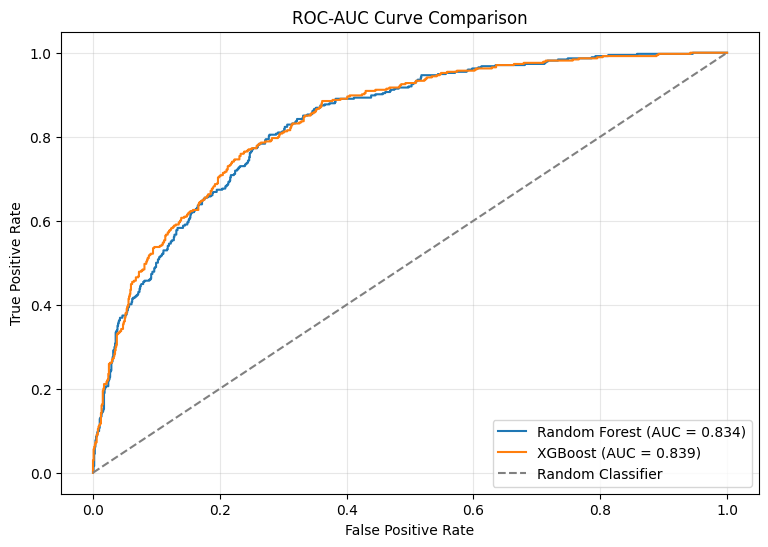

In [35]:
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Curve Comparison")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [36]:
feature_names = (
    rf_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)

rf_importances = (
    rf_pipeline
    .named_steps['classifier']
    .feature_importances_
)

rf_feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importances
})

rf_feature_importance['Feature'] = (
    rf_feature_importance['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

rf_top10 = rf_feature_importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

print(rf_top10)

                           Feature  Importance
1                           tenure    0.128059
3                     TotalCharges    0.125027
2                   MonthlyCharges    0.099909
36         Contract_Month-to-month    0.093120
18               OnlineSecurity_No    0.046546
38               Contract_Two year    0.045870
27                  TechSupport_No    0.039956
16     InternetService_Fiber optic    0.036674
43  PaymentMethod_Electronic check    0.029414
21                 OnlineBackup_No    0.018238


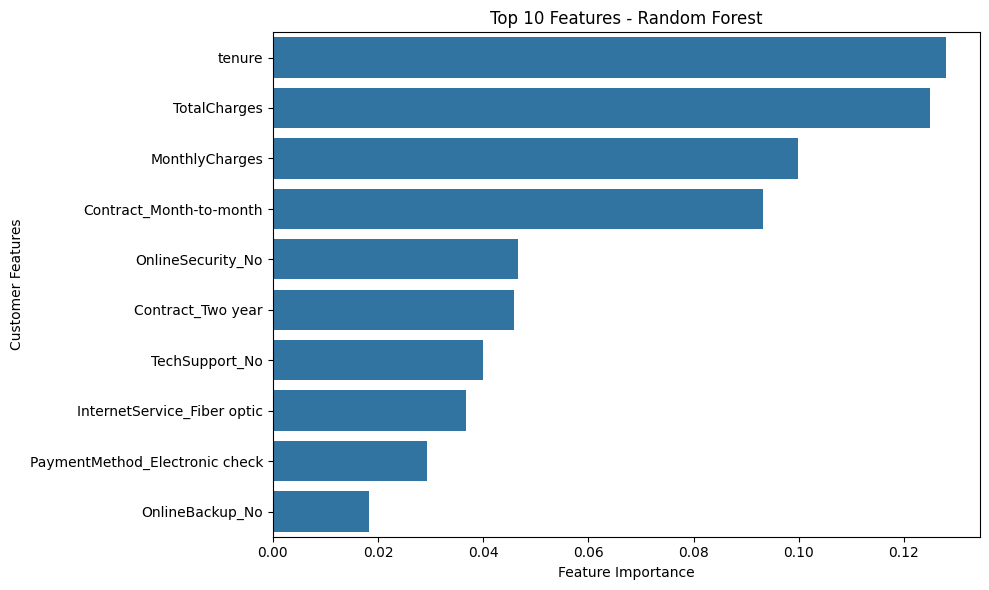

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_top10,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Features - Random Forest")

plt.xlabel("Feature Importance")

plt.ylabel("Customer Features")

plt.tight_layout()

plt.show()

In [38]:
feature_names = (
    xgb_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)

xgb_importances = (
    xgb_pipeline
    .named_steps['classifier']
    .feature_importances_
)

xgb_feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_importances
})

xgb_feature_importance['Feature'] = (
    xgb_feature_importance['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

xgb_top10 = xgb_feature_importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

print(xgb_top10)

                               Feature  Importance
36             Contract_Month-to-month    0.274297
16         InternetService_Fiber optic    0.113620
18                   OnlineSecurity_No    0.087397
38                   Contract_Two year    0.045961
27                      TechSupport_No    0.042877
15                 InternetService_DSL    0.033374
35                 StreamingMovies_Yes    0.029613
19  OnlineSecurity_No internet service    0.027307
37                   Contract_One year    0.027066
43      PaymentMethod_Electronic check    0.021981


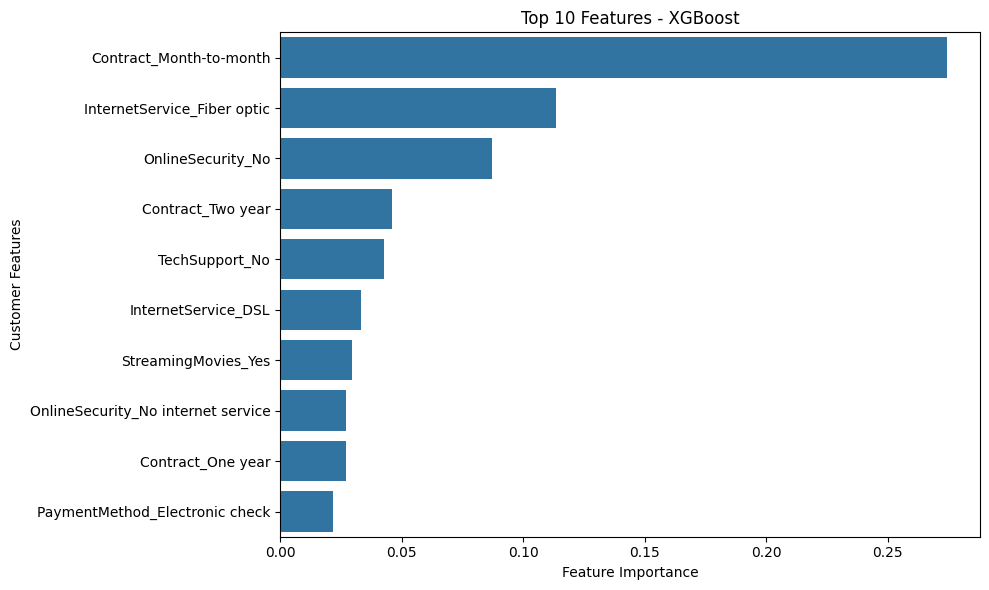

In [39]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_top10,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Features - XGBoost")

plt.xlabel("Feature Importance")

plt.ylabel("Customer Features")

plt.tight_layout()

plt.show()

In [40]:
final_results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],

    'CV ROC-AUC': [
        rf_scores.mean(),
        xgb_scores.mean()
    ],

    'Test ROC-AUC': [
        rf_auc,
        xgb_auc
    ],

    'Test Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ]
})

print("FINAL MODEL PERFORMANCE")

print(final_results.to_string(index=False))

best_model = (
    final_results
    .loc[
        final_results['Test ROC-AUC'].idxmax(),
        'Model'
    ]
)

print("\nBest Performing Model:", best_model)

FINAL MODEL PERFORMANCE
        Model  CV ROC-AUC  Test ROC-AUC  Test Accuracy
Random Forest    0.837201      0.834064       0.779276
      XGBoost    0.840918      0.838948       0.758694

Best Performing Model: XGBoost
